In [13]:
import pandas as pd

df = pd.read_csv("../data/processed/rotulado_v1.csv").dropna(subset=["categoria"])
df = df[df["fonte"].isin(["conta", "cartao"])]   

df["descricao"].str.split(" - ").str[0].value_counts().head(15)


descricao
Compra no débito                   201
Transferência enviada pelo Pix      25
Compra Meio De Transporte            9
Aplicação                            8
Pagamento de boleto efetuado         7
Cashback                             7
Transferência recebida pelo Pix      6
Resgate                              5
Pagamento efetuado                   3
Estorno                              2
Pix recebido                         1
Pix enviado                          1
Pix enviado devolvido                1
Crédito liberado                     1
NETFLIX.COM                          1
Name: count, dtype: int64

In [2]:
df["descricao"].str.split().str[-1].value_counts().head(15)

descricao
Bra         204
LTDA         11
Sa            8
PESSOA        6
S.A.          5
01/03         5
-CT           5
A             4
01/02         4
02/06         4
R             3
BERNARDO      3
SBC           3
01/06         3
(0077)        2
Name: count, dtype: int64

In [3]:
import re

t = re.sub(r"([a-z])(\d)", r"\1 \2", "drogasil2705")

re.sub(r"\d+", "", t)

'drogasil '

In [4]:
re.sub(r"\s+bra$", "", "sao paulo bra")

'sao paulo'

In [5]:
re.sub(r"no estabelecimento\s*+\s*", " ", "no estabelecimento marmel mf indaiatuba")

' marmel mf indaiatuba'

In [6]:
re.sub(r"\d{2}/\d{2}", " ", "01/03")

' '

In [7]:
re.sub(r"\d+ de \d+", " ", "05 de 10")

' '

In [8]:
re.sub(r"-ct$", "", "Basquete-ct")

'Basquete'

In [9]:
re.sub(r"[^\w\s]", " ", "ifd*pizzaria - netflix.com (sp)")

'ifd pizzaria   netflix com  sp '

In [10]:
import sys
sys.path.append("..")            
from src.limpeza import limpar

exemplos = [
    "Compra no débito - Drogasil2705 Sao Bernardo Bra",
    "Compra no débito - No Estabelecimento Marmel Mf Indaiatuba Bra",
    "LATAM AIR*0000 01/03",
    "ALLIANZ SEGU*04 de 10",
    "FORT 585 SP -CT",
    "Pix enviado - PESSOA - NU PAGAMENTOS - IP",
]
for e in exemplos:
    print(f"{e!r:65} -> {limpar(e)!r}")

'Compra no débito - Drogasil2705 Sao Bernardo Bra'                -> 'drogasil sao bernardo'
'Compra no débito - No Estabelecimento Marmel Mf Indaiatuba Bra'  -> 'marmel mf indaiatuba'
'LATAM AIR*0000 01/03'                                            -> 'latam air'
'ALLIANZ SEGU*04 de 10'                                           -> 'allianz segu'
'FORT 585 SP -CT'                                                 -> 'fort sp'
'Pix enviado - PESSOA - NU PAGAMENTOS - IP'                       -> 'pix enviado pessoa nu pagamentos ip'


In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

X, y = df["descricao"], df["categoria"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # o MESMO cv do baseline

baseline = make_pipeline(
    TfidfVectorizer(lowercase=True),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
com_limpeza = make_pipeline(
    TfidfVectorizer(preprocessor=limpar),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)

baseline_letras = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
letras_limpeza = make_pipeline(
    TfidfVectorizer(preprocessor=limpar, analyzer="char_wb", ngram_range=(2, 4)),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
for nome, modelo in [("palavras", baseline), ("palavras + limpeza", com_limpeza),
                     ("letras", baseline_letras), ("letras + limpeza", letras_limpeza)]:
    f1 = cross_val_score(modelo, X, y, cv=cv, scoring="f1_macro")
    acc = cross_val_score(modelo, X, y, cv=cv, scoring="accuracy")
    print(f"{nome:20} F1 macro {f1.mean():.3f} ± {f1.std():.3f} | acurácia {acc.mean():.3f} ± {acc.std():.3f}")

palavras             F1 macro 0.581 ± 0.040 | acurácia 0.618 ± 0.026
palavras + limpeza   F1 macro 0.614 ± 0.046 | acurácia 0.660 ± 0.025
letras               F1 macro 0.638 ± 0.095 | acurácia 0.664 ± 0.049
letras + limpeza     F1 macro 0.644 ± 0.084 | acurácia 0.682 ± 0.032


In [15]:
import re

REGRAS = [
    ("compra no débito",    r"compra no d[ée]bito\s*-\s*", " "),
    ("bra no fim",          r"\s+bra$",                    " "),
    ("no estabelecimento",  r"no estabelecimento\s*",      " "),
    ("parcela 01/03",       r"\d{2}/\d{2}",                " "),
    ("parcela 05 de 10",    r"\d+ de \d+",                 " "),
    ("-ct do Itaú",         r"-ct\b",                      ""),
    ("separa letra/número", r"([a-z])(\d)",                r"\1 \2"),
    ("apaga números",       r"\d+",                        " "),
    ("pontuação",           r"[^\w\s]",                    " "),
    ("espaços repetidos",   r"\s+",                        " "),
]

def limpar_sem(texto, pular=None):
    t = texto.lower()
    for nome, padrao, troca in REGRAS:
        if nome != pular:                  # pula só a regra escolhida
            t = re.sub(padrao, troca, t)
    return t.strip()

def nota(preprocessador):
    modelo = make_pipeline(TfidfVectorizer(preprocessor=preprocessador),
                           LogisticRegression(max_iter=1000, class_weight="balanced"))
    return cross_val_score(modelo, X, y, cv=cv, scoring="f1_macro").mean()

completa = nota(limpar_sem)
linhas = []
for nome, _, _ in REGRAS:
    sem = nota(lambda t, n=nome: limpar_sem(t, n))
    linhas.append({"regra desligada": nome, "F1 macro": round(sem, 3), "diferença": round(sem - completa, 3)})

print(f"Com todas as regras: {completa:.3f}")
pd.DataFrame(linhas).sort_values("diferença")

Com todas as regras: 0.614


,regra desligada,F1 macro,diferença
2,no estabelecimento,0.599,-0.014
0,compra no débito,0.608,-0.006
1,bra no fim,0.610,-0.003
5,-ct do Itaú,0.611,-0.003
3,parcela 01/03,0.614,0.000
6,separa letra/número,0.614,0.000
7,apaga números,0.614,-0.000
8,pontuação,0.614,0.000
9,espaços repetidos,0.614,0.000
4,parcela 05 de 10,0.616,0.002


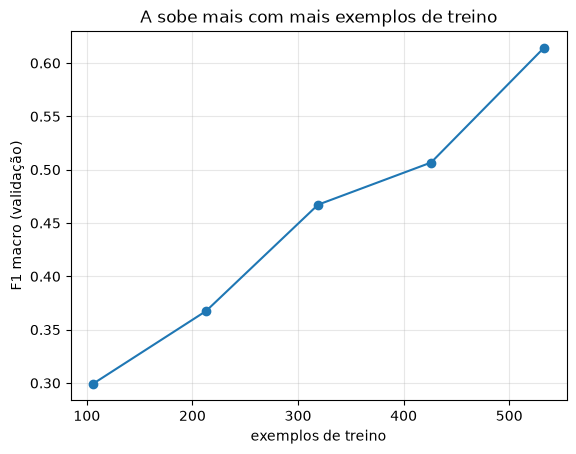

In [17]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

tamanhos, notas_treino, notas_teste = learning_curve(
    com_limpeza, X, y, cv=cv, scoring="f1_macro", train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0])

plt.plot(tamanhos, notas_teste.mean(axis=1), marker="o")
plt.xlabel("exemplos de treino")
plt.ylabel("F1 macro (validação)")
plt.title("A sobe mais com mais exemplos de treino")
plt.grid(alpha=0.3)
plt.show()